# 02 · Exploratory data analysis — Mexican small-cargo EV survey

This is the **visual narrative notebook**. The first three figures reproduce the layout and titles of the original audited notebook: *survey eligibility*, *firm and fleet composition*, and *observed EV use versus consideration*. All figures use the centrally managed navy / slate-blue / muted-gold palette and are saved as PNG **and** SVG.

Charts that tell a single research story are grouped into 2–3 panels. Descriptive rates always use the valid denominator for the relevant question.

## Reproducible setup

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'ev_research').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.ev_research.data import load_survey, sample_audit, cleaning_audit
from src.ev_research.config import FIGURES, TABLES, FEATURE_SETS, SOURCE_INDEX
from src.ev_research.plotting_style import apply_style
from src.ev_research.statistics import prevalence_table, assumptions_audit, fisher_associations, sensitivity_table
from src.ev_research.figures import *
apply_style()
raw, unique, eligible = load_survey()
print(f'Raw: {len(raw)} | Distinct: {len(unique)} | Eligible: {len(eligible)}')
def show_figure(path, width=1150):
    """Display the exact saved PNG (also exported as vector SVG)."""
    assert path.exists(), f'Missing figure: {path}'
    display(Image(filename=str(path), width=width))


Raw: 105 | Distinct: 92 | Eligible: 62


## Figure 1 · Survey eligibility and respondent coverage

The unique eligible survey, rather than total submitted forms, forms the main descriptive sample.

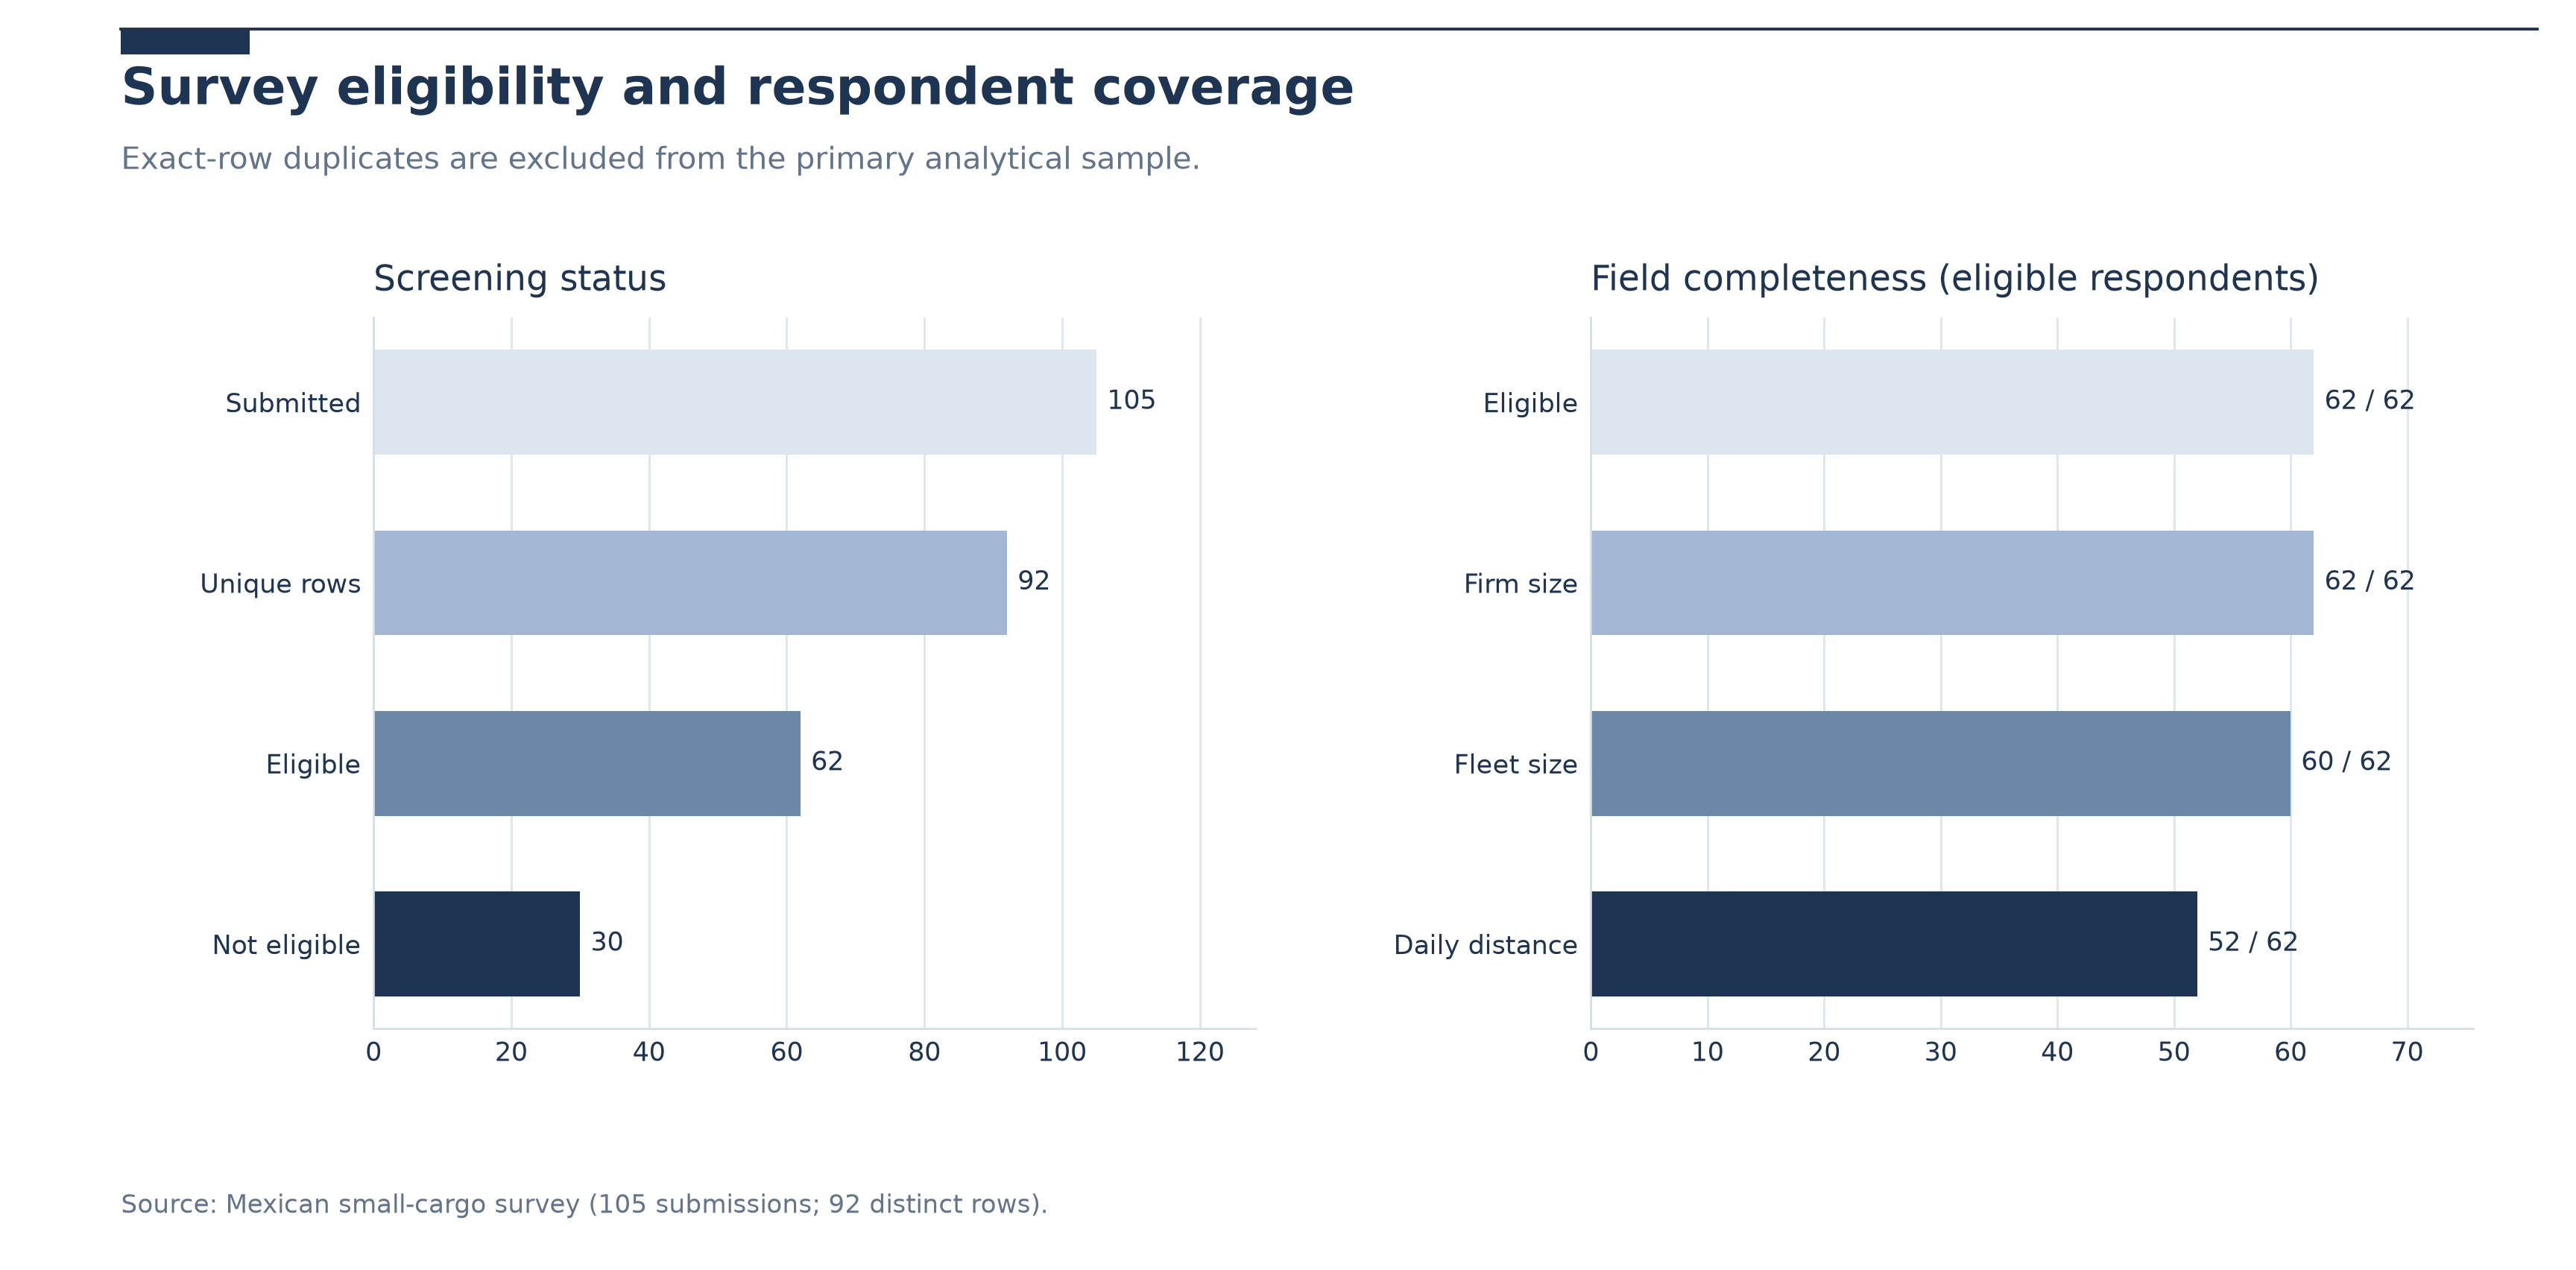

In [2]:
plot_eligibility_and_coverage(raw, unique, eligible)
show_figure(FIGURES/'01_data_quality'/'01_survey_eligibility_and_coverage.png')

## Figure 2 · Normalized operator and fleet composition

In the original sample, 29 small, 11 medium, and 22 large companies satisfy the eligibility screen. Fleet size is measured in questionnaire-defined bins, not as a continuous count.

firm_size
Small     29
Large     22
Medium    11
Name: count, dtype: int64
fleet_size
1-10       31
11-50      15
>400        7
200-400     4
51-200      3
NaN         2
Name: count, dtype: int64


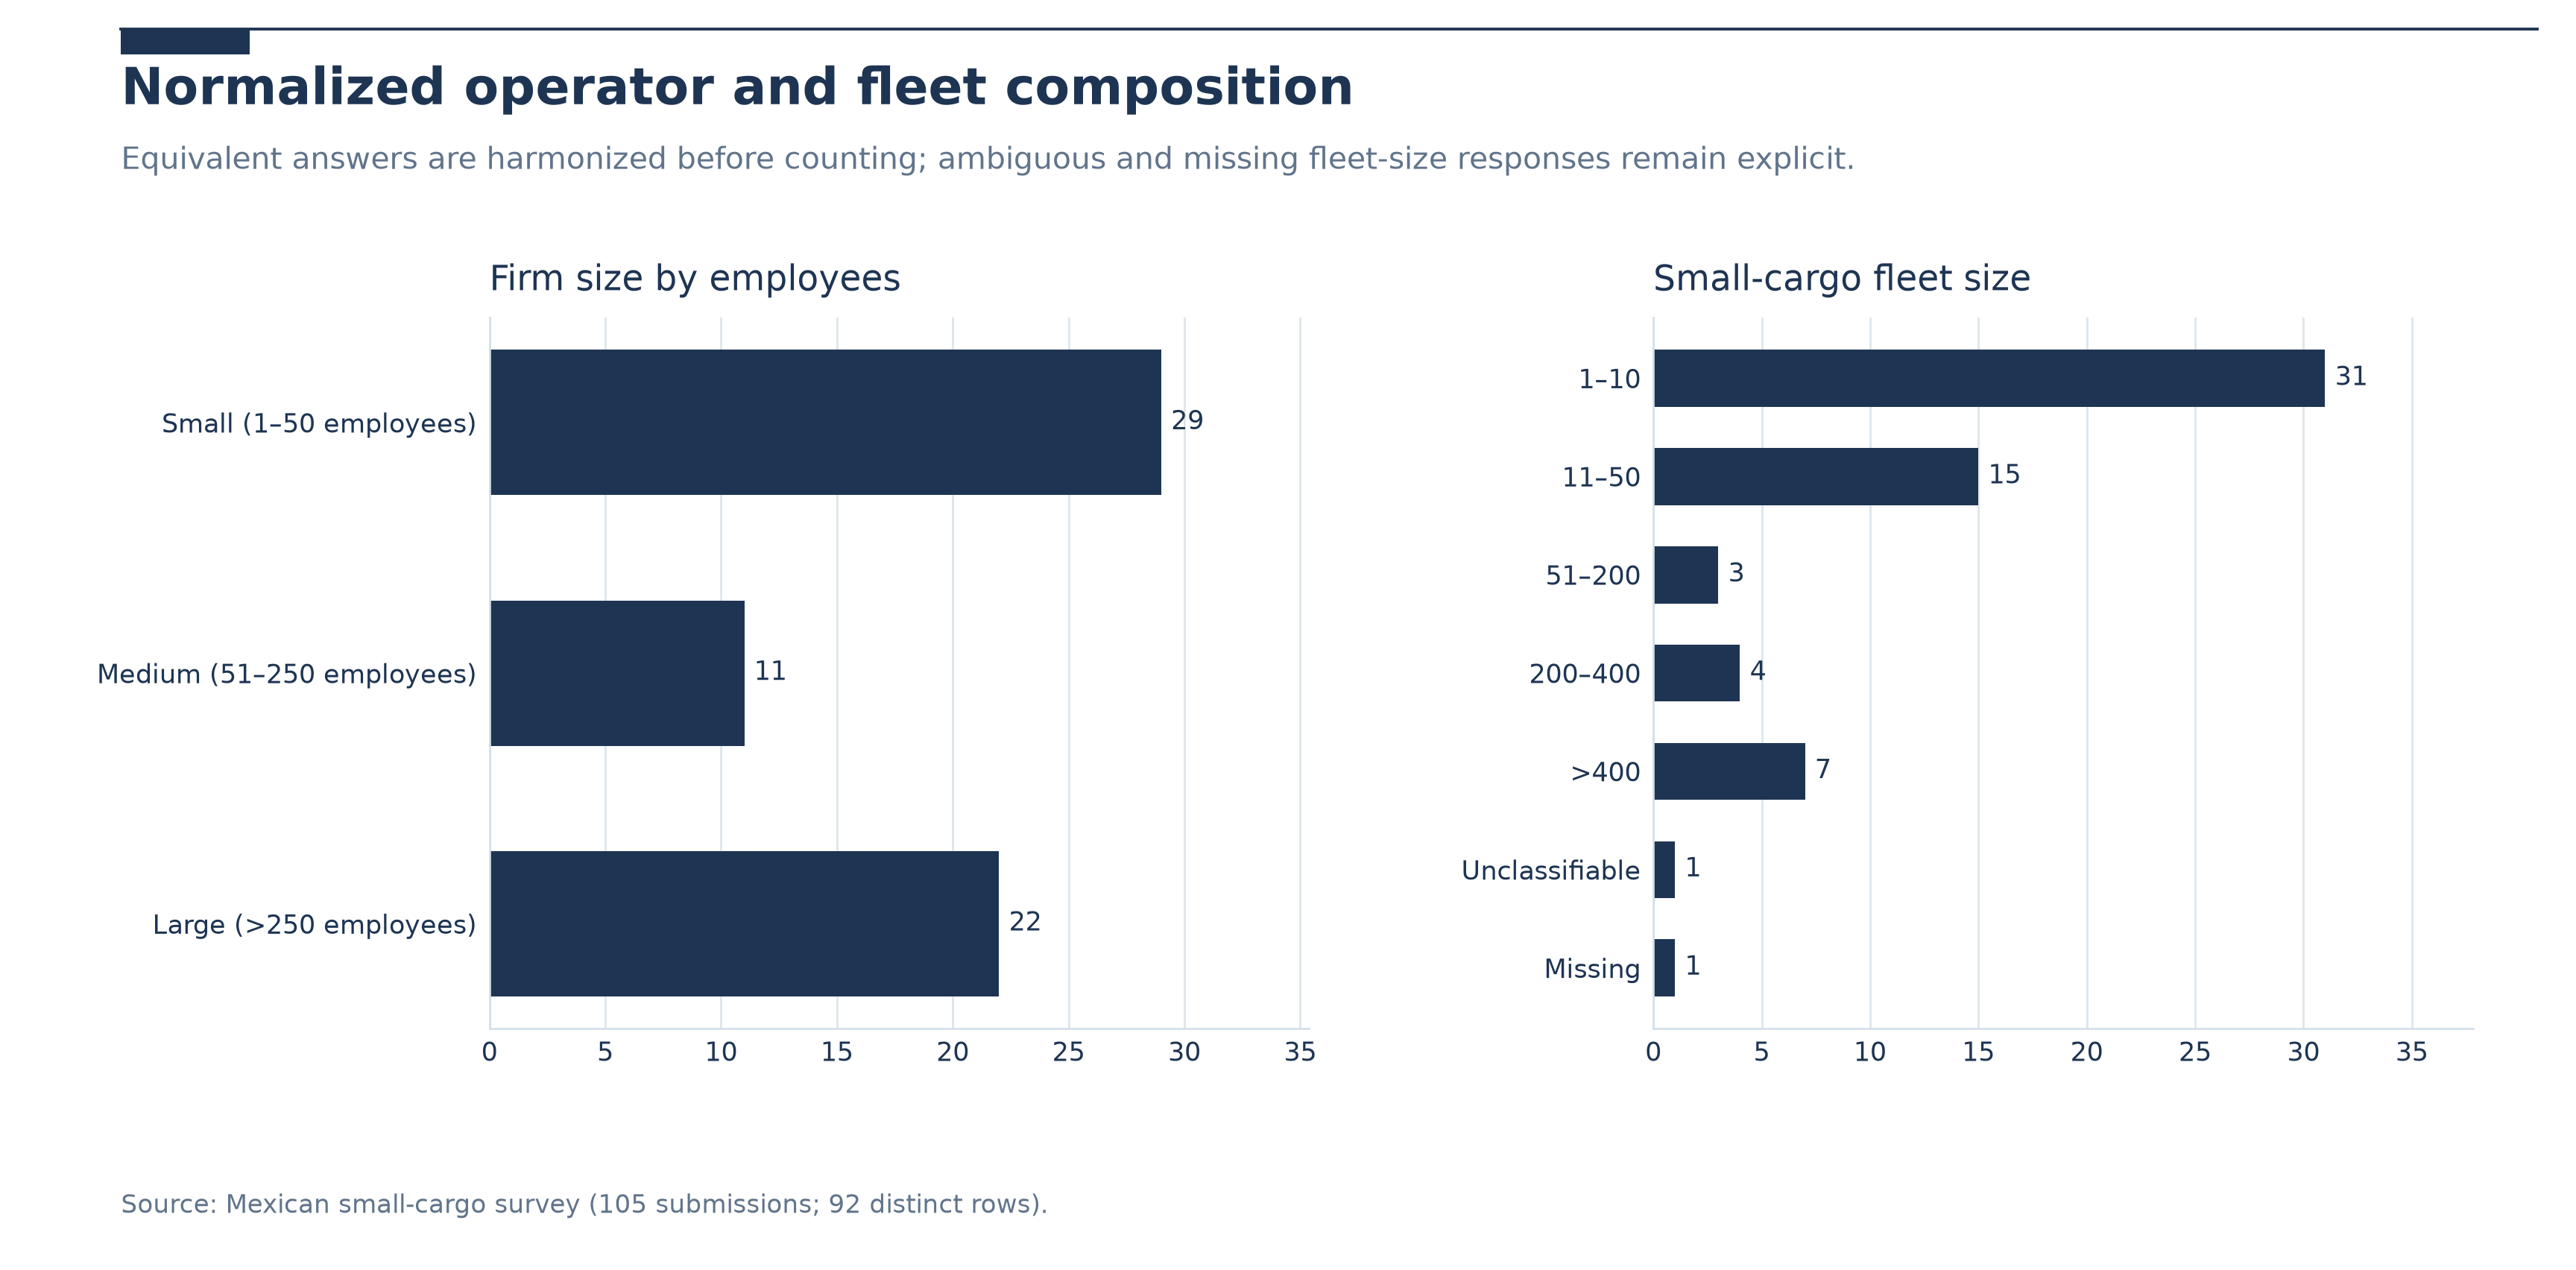

In [3]:
print(eligible.firm_size.value_counts(dropna=False))
print(eligible.fleet_size.value_counts(dropna=False))
plot_operator_and_fleet(eligible)
show_figure(FIGURES/'02_eda'/'01_operator_and_fleet_composition.png')

## Figure 3 · Observed EV use and consideration

**Current EV use ≠ considered EV inclusion.** Current adopters may report consideration; these two marginal percentages are not a transition probability.

,outcome,positive,negative,n,rate,wilson_95_low,wilson_95_high
0,ev_use,15,45,60,0.250000,0.157765,0.372321
1,ev_consideration,34,25,59,0.576271,0.449345,0.693873


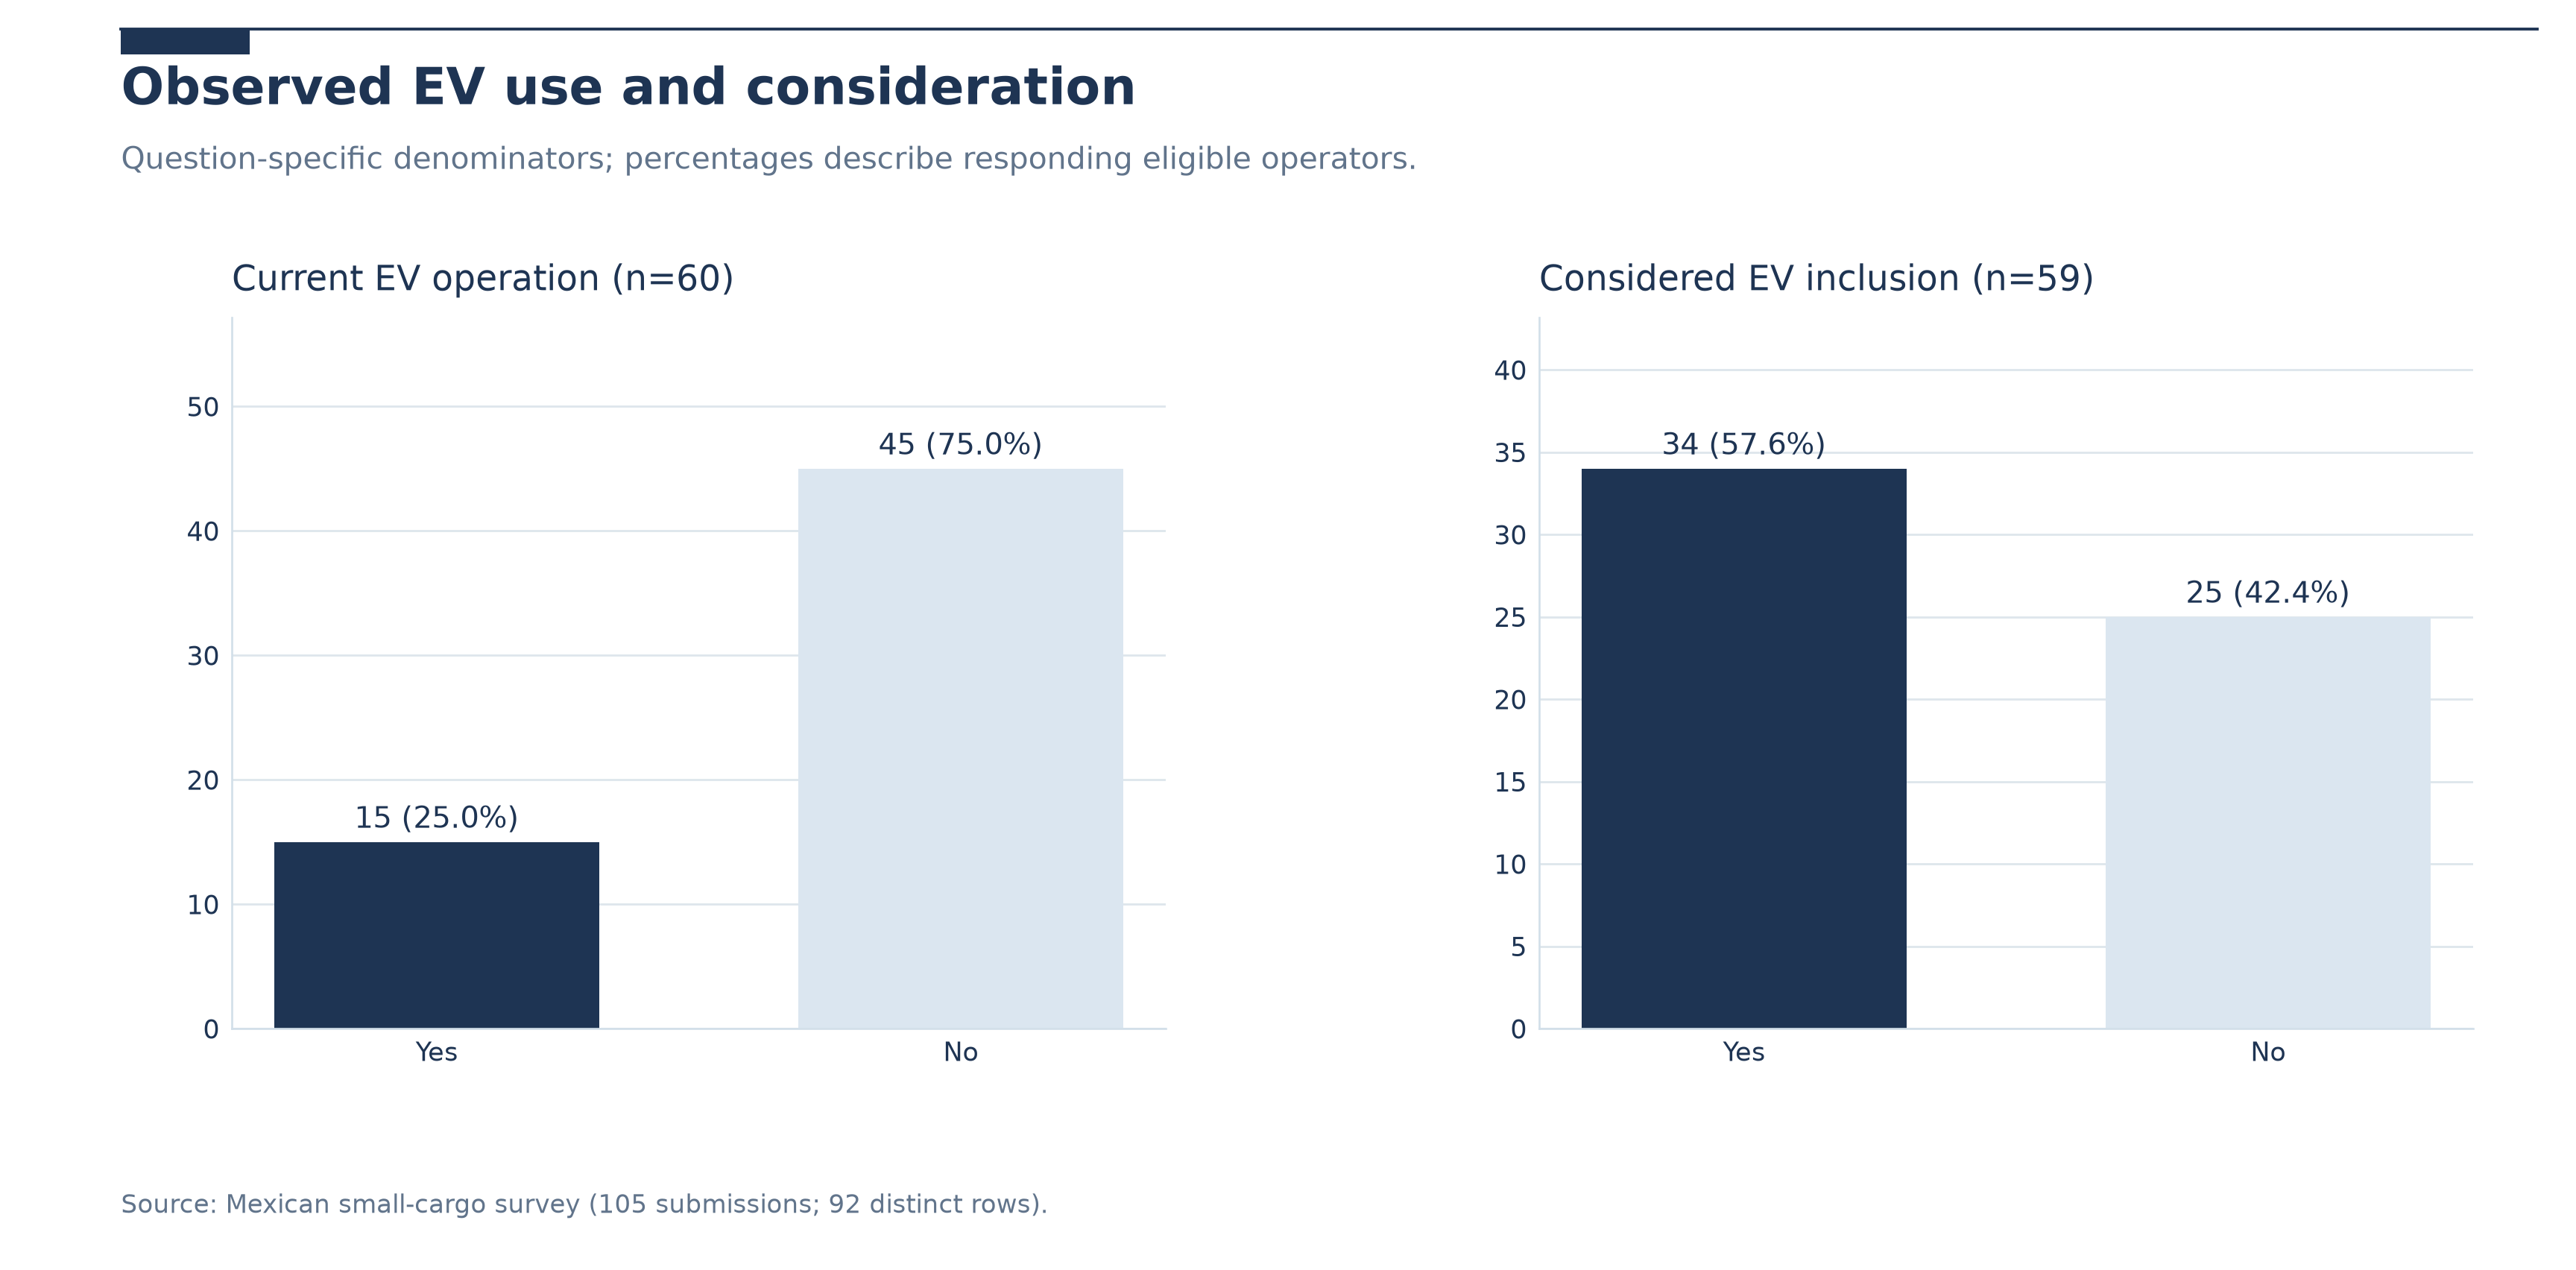

In [4]:
display(prevalence_table(eligible))
plot_observed_ev_outcomes(eligible)
show_figure(FIGURES/'01_data_quality'/'02_observed_ev_use_and_consideration.png')

## Figure 4 · Daily distance and conventional-vehicle purchase cost

Use the questionnaire's reported categories. Distance data have varying units and ambiguous range definitions; acquisition costs cannot by themselves establish EV total cost of ownership.

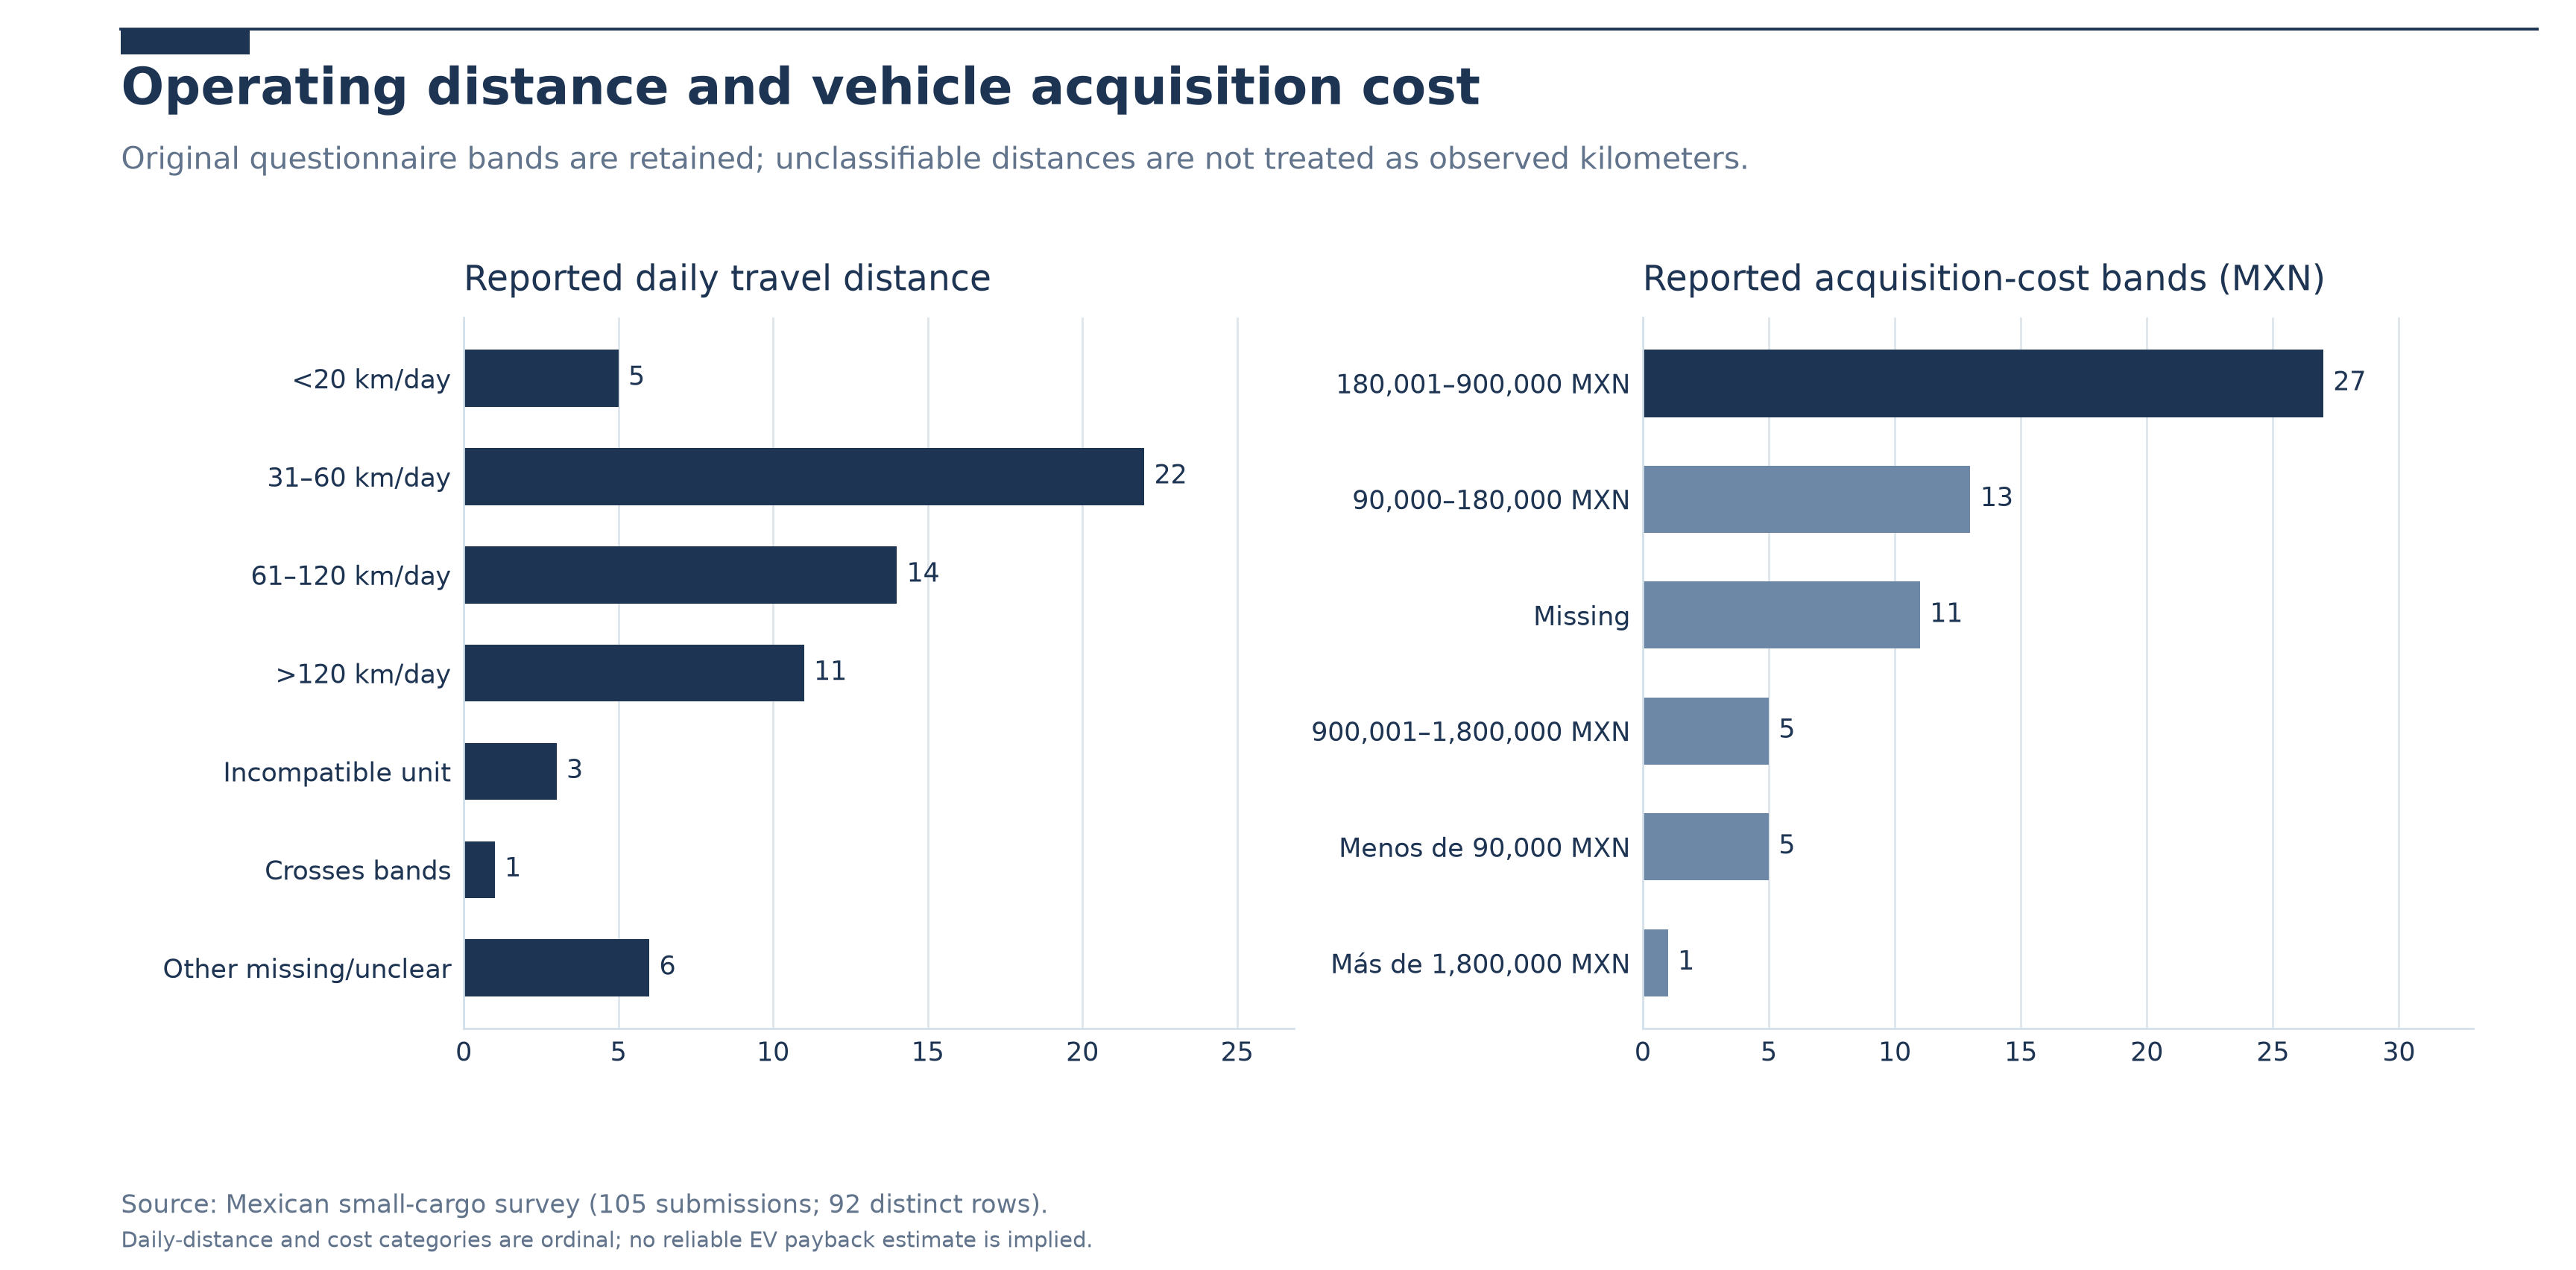

In [5]:
plot_distance_and_cost(eligible)
show_figure(FIGURES/'02_eda'/'02_distance_and_acquisition_cost.png')

## Figure 5 · Perceived barriers, perceived benefits and route organization

Multi-select choices are not exclusive. Their total may exceed the number answering. These are perceptions, not causal estimates or field-verified charging availability.

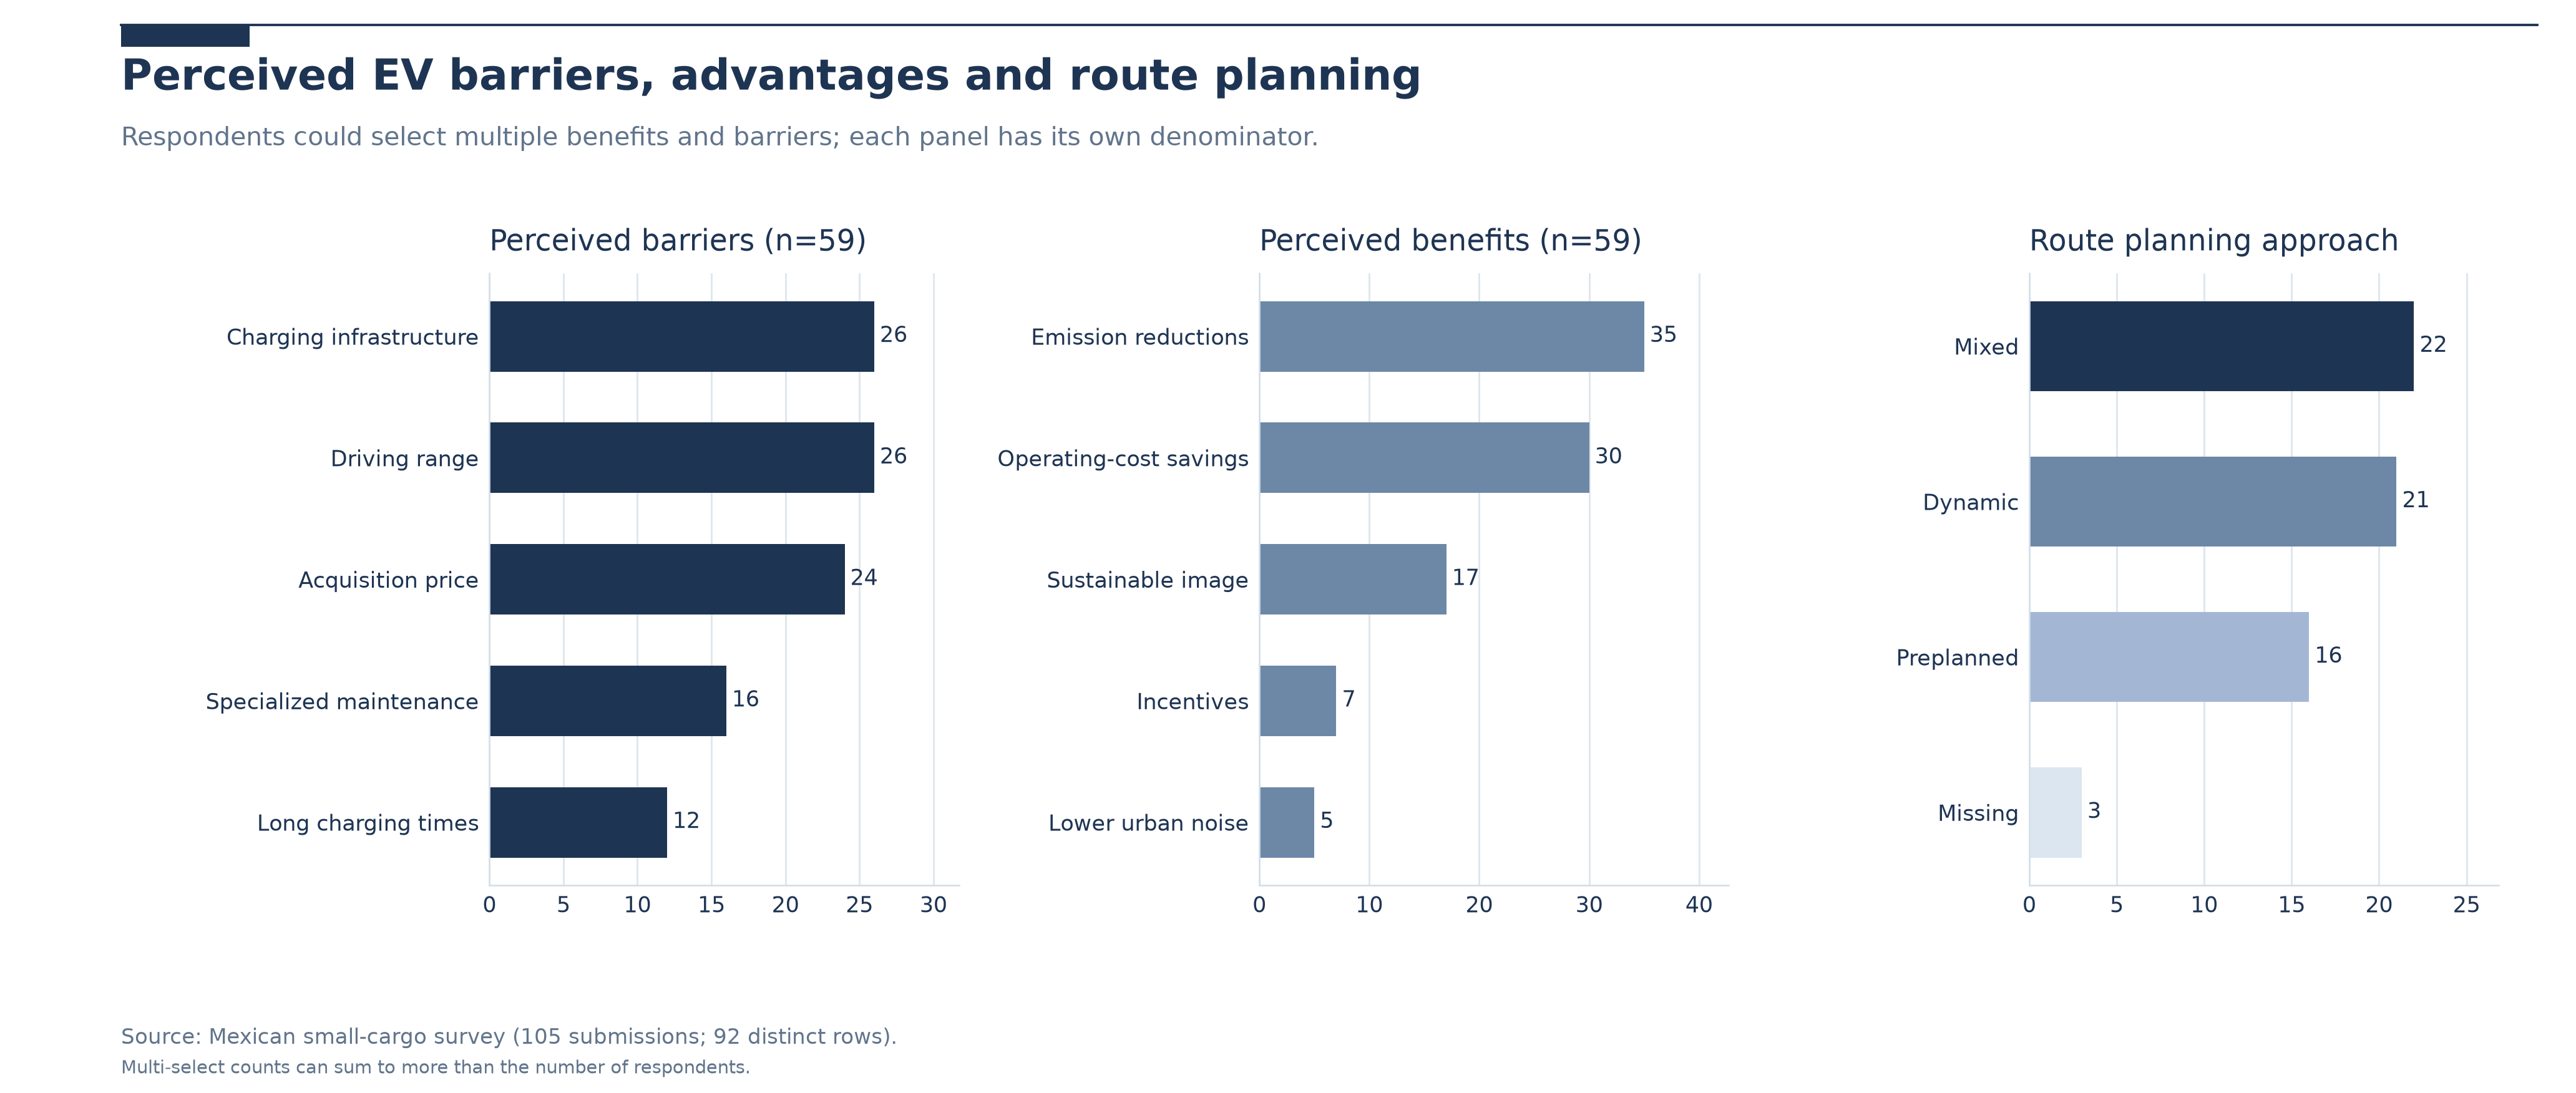

In [6]:
plot_barriers_benefits_and_operations(eligible)
show_figure(FIGURES/'02_eda'/'03_barriers_benefits_and_route_planning.png')

## Figure 6 · Current EV use by company segment

Rates are computed within each segment **with valid current-use responses**; sample sizes accompany all bars.

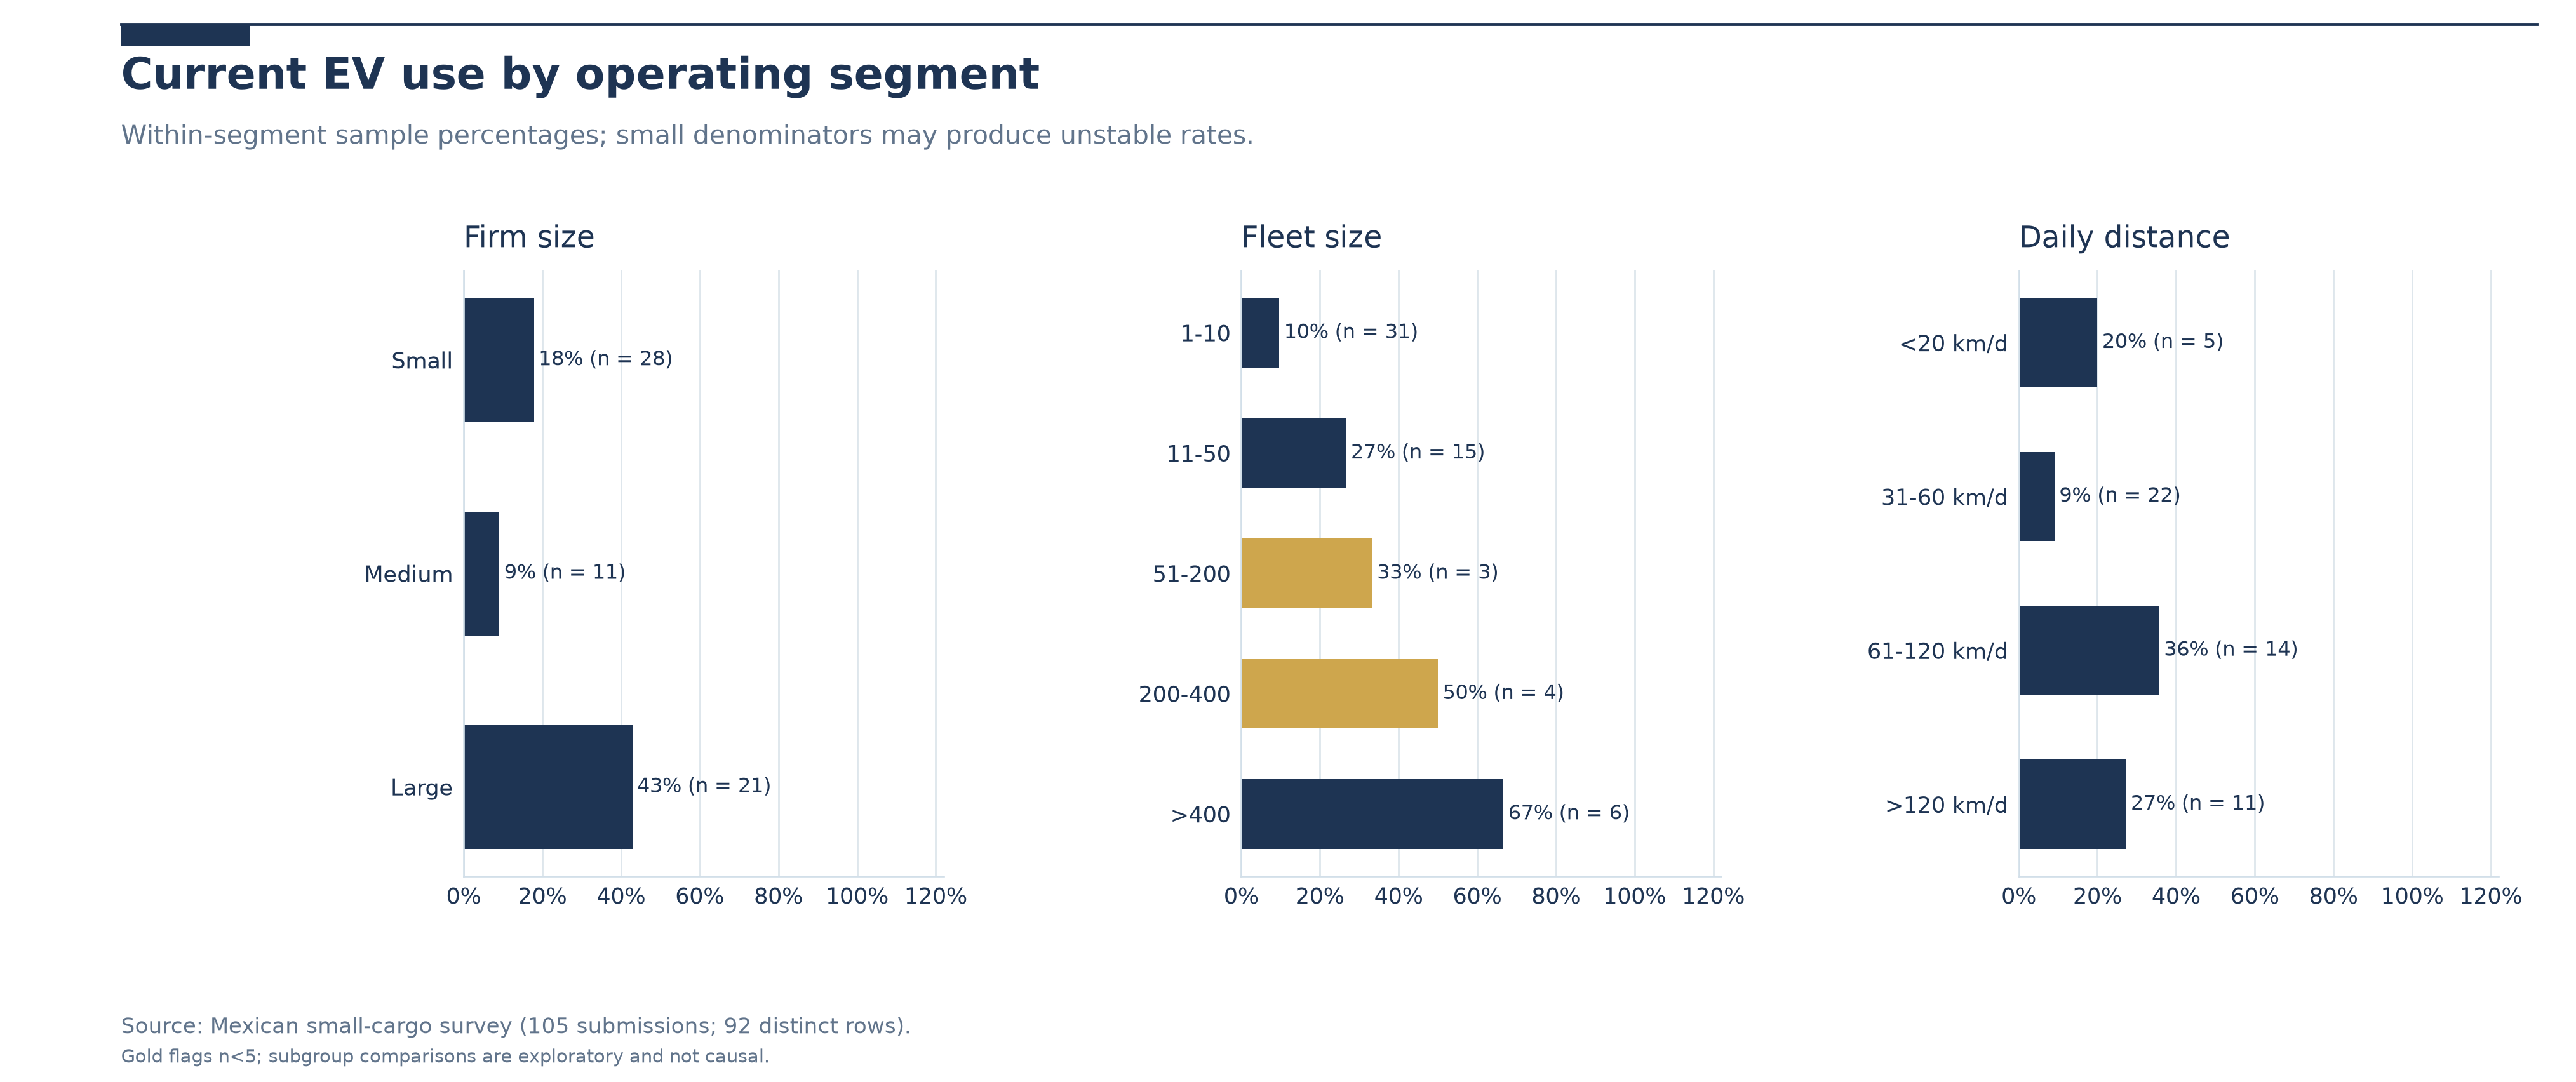

In [7]:
plot_segment_rates(eligible,'ev_use')
show_figure(FIGURES/'03_ev_use'/'01_operator_segment_rates.png')

## Figure 7 · Consideration by company segment

The same stratification is applied independently to the consideration target. Rates in small cells are illustrative, not stable population estimates.

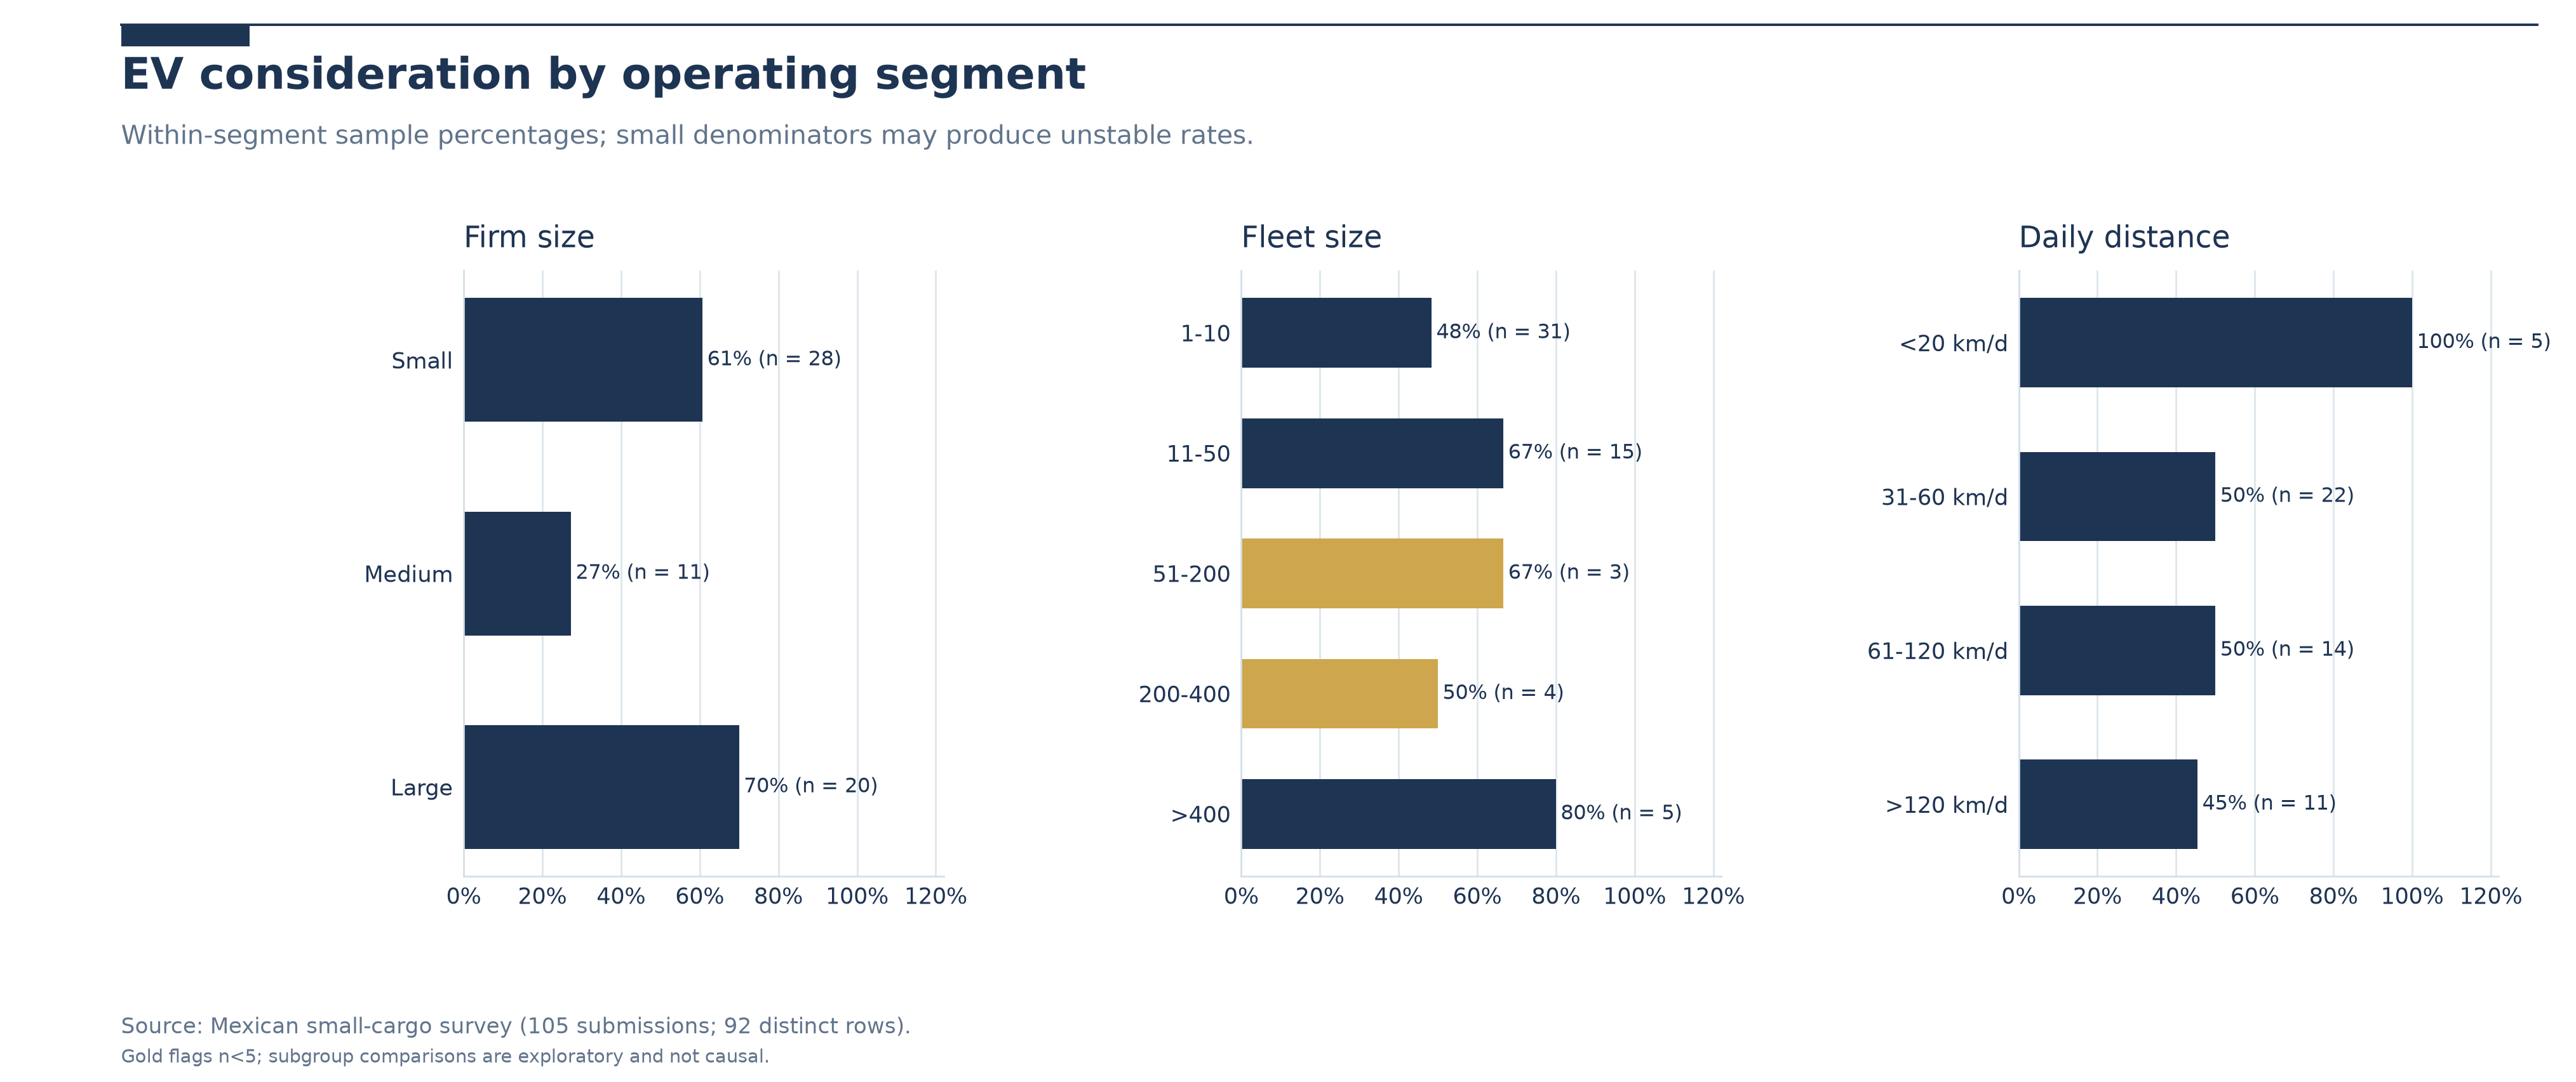

In [8]:
plot_segment_rates(eligible,'ev_consideration')
show_figure(FIGURES/'04_ev_consideration'/'01_operator_segment_rates.png')

## Figure 8 · Data-quality decisions

Explicitly identify which variables were successfully harmonized before drawing conclusions from a visualization.

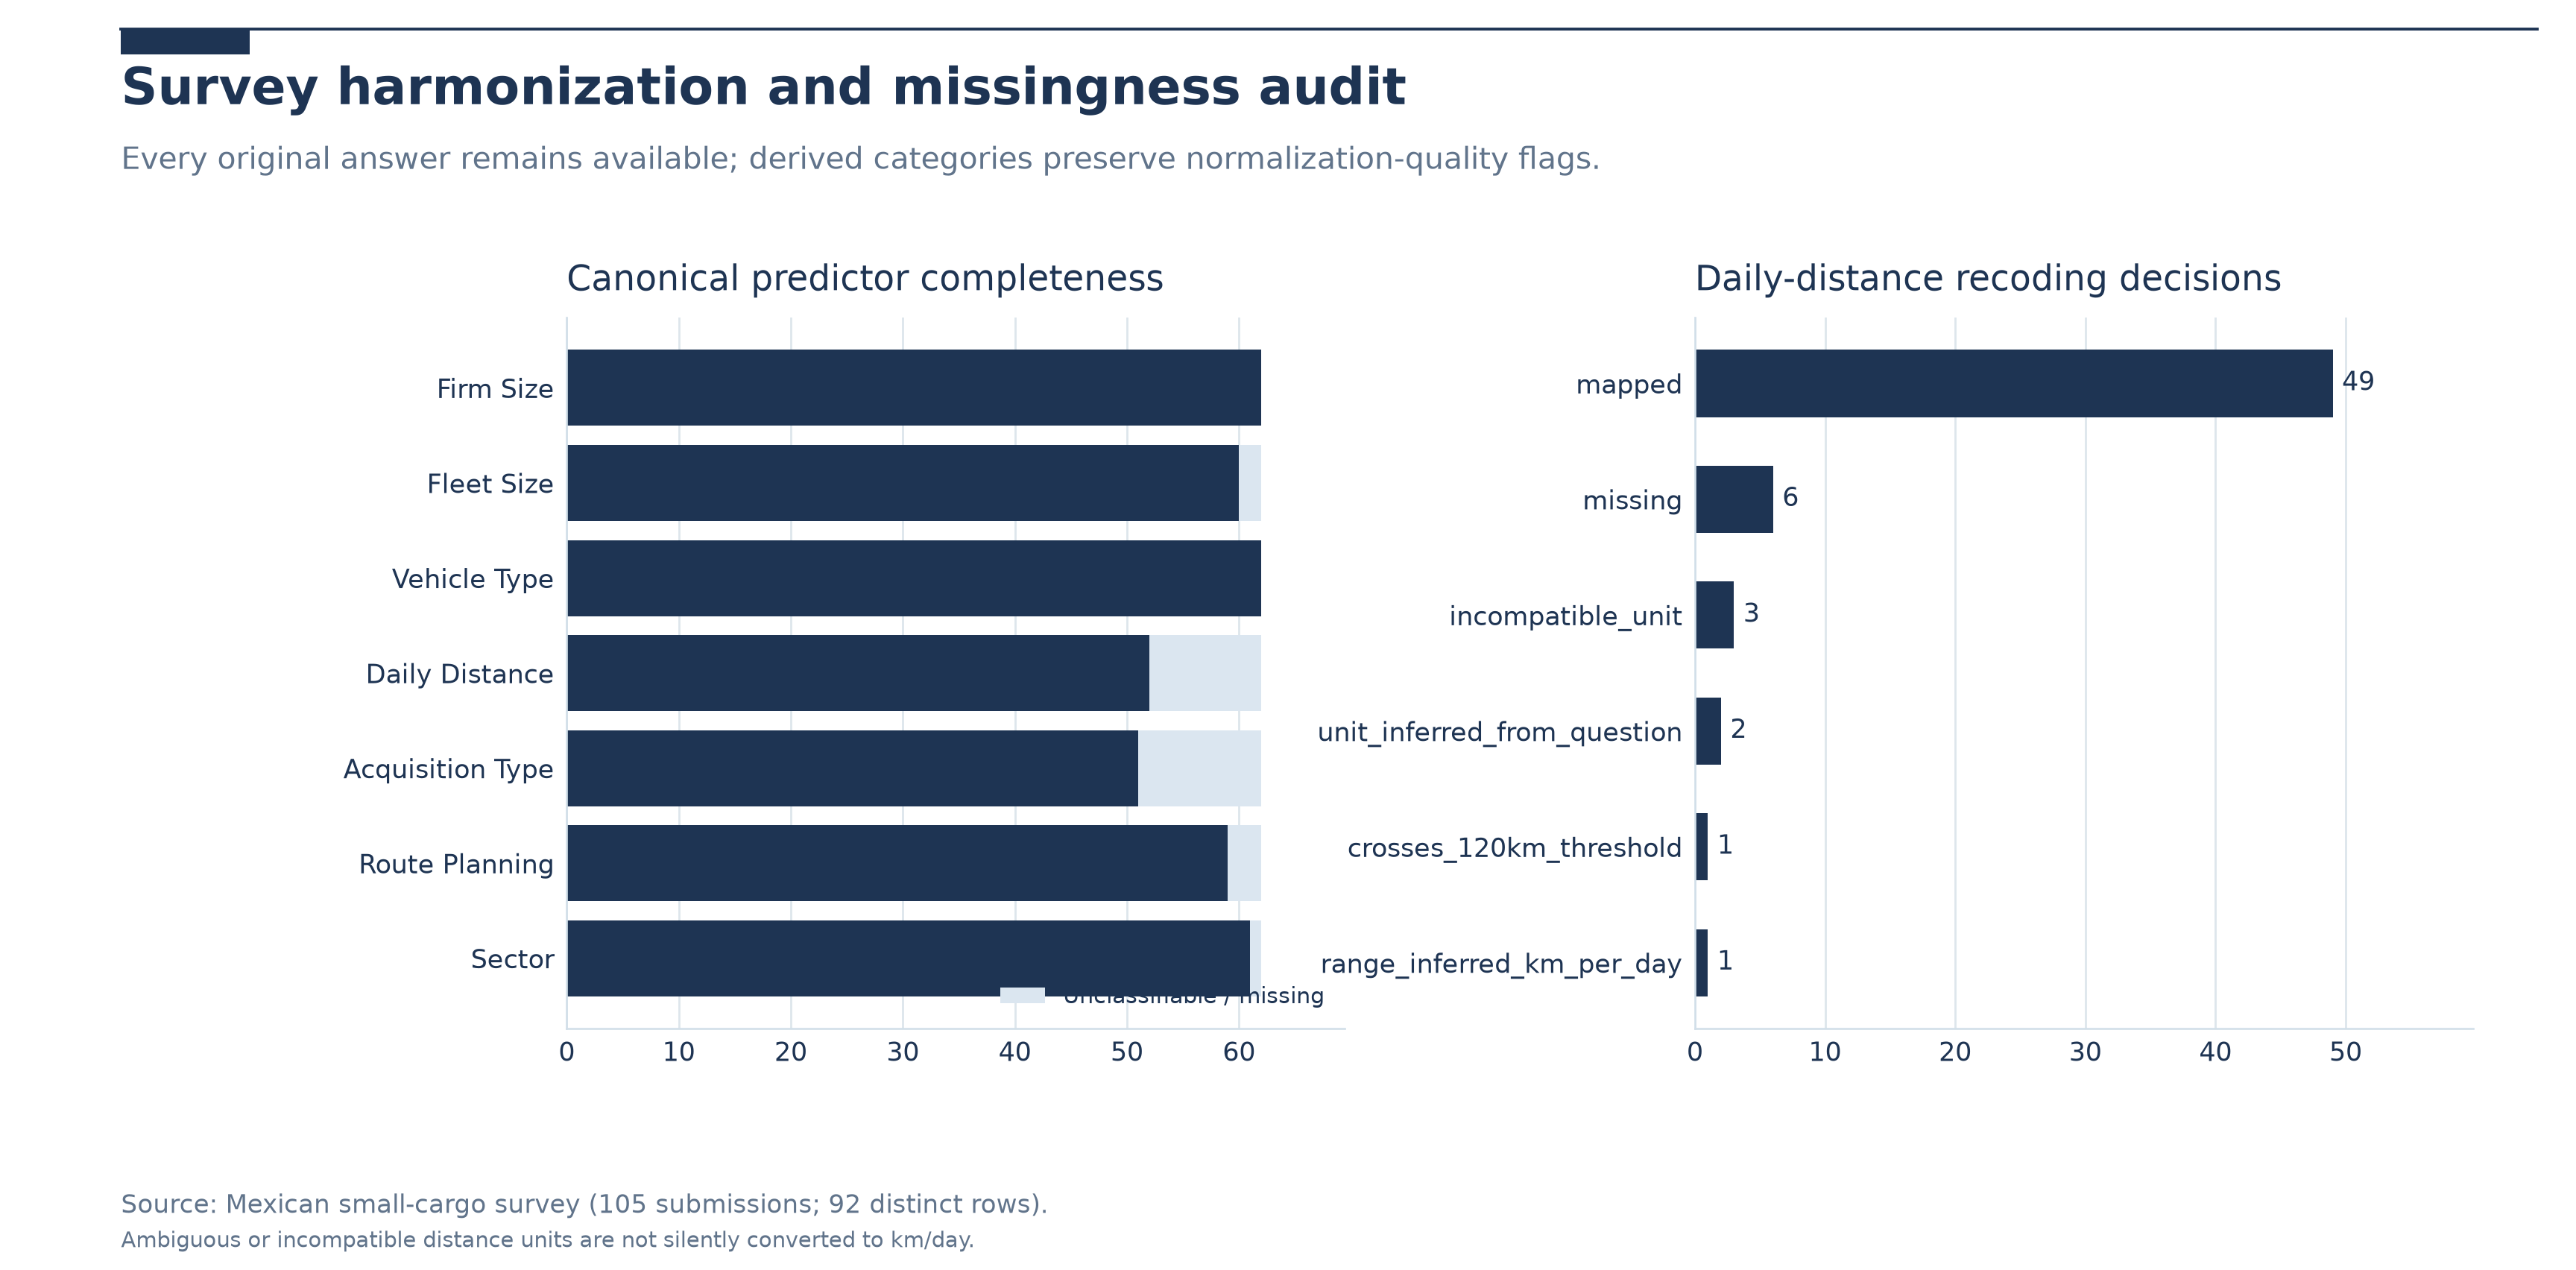

In [9]:
plot_cleaning_quality(eligible)
show_figure(FIGURES/'01_data_quality'/'03_normalization_and_missingness.png')

## Figure 9 · Sensitivity: duplicates and consideration among non-adopters

Do not interpret comparison across different respondent sets as a longitudinal EV transition.

,analysis,outcome,n,positive,rate
0,deduplicated_main,ev_use,60,15,0.250000
1,deduplicated_main,ev_consideration,59,34,0.576271
2,exact_duplicates_retained,ev_use,69,22,0.318841
3,exact_duplicates_retained,ev_consideration,67,42,0.626866
4,current_nonadopters_only,ev_consideration,44,19,0.431818


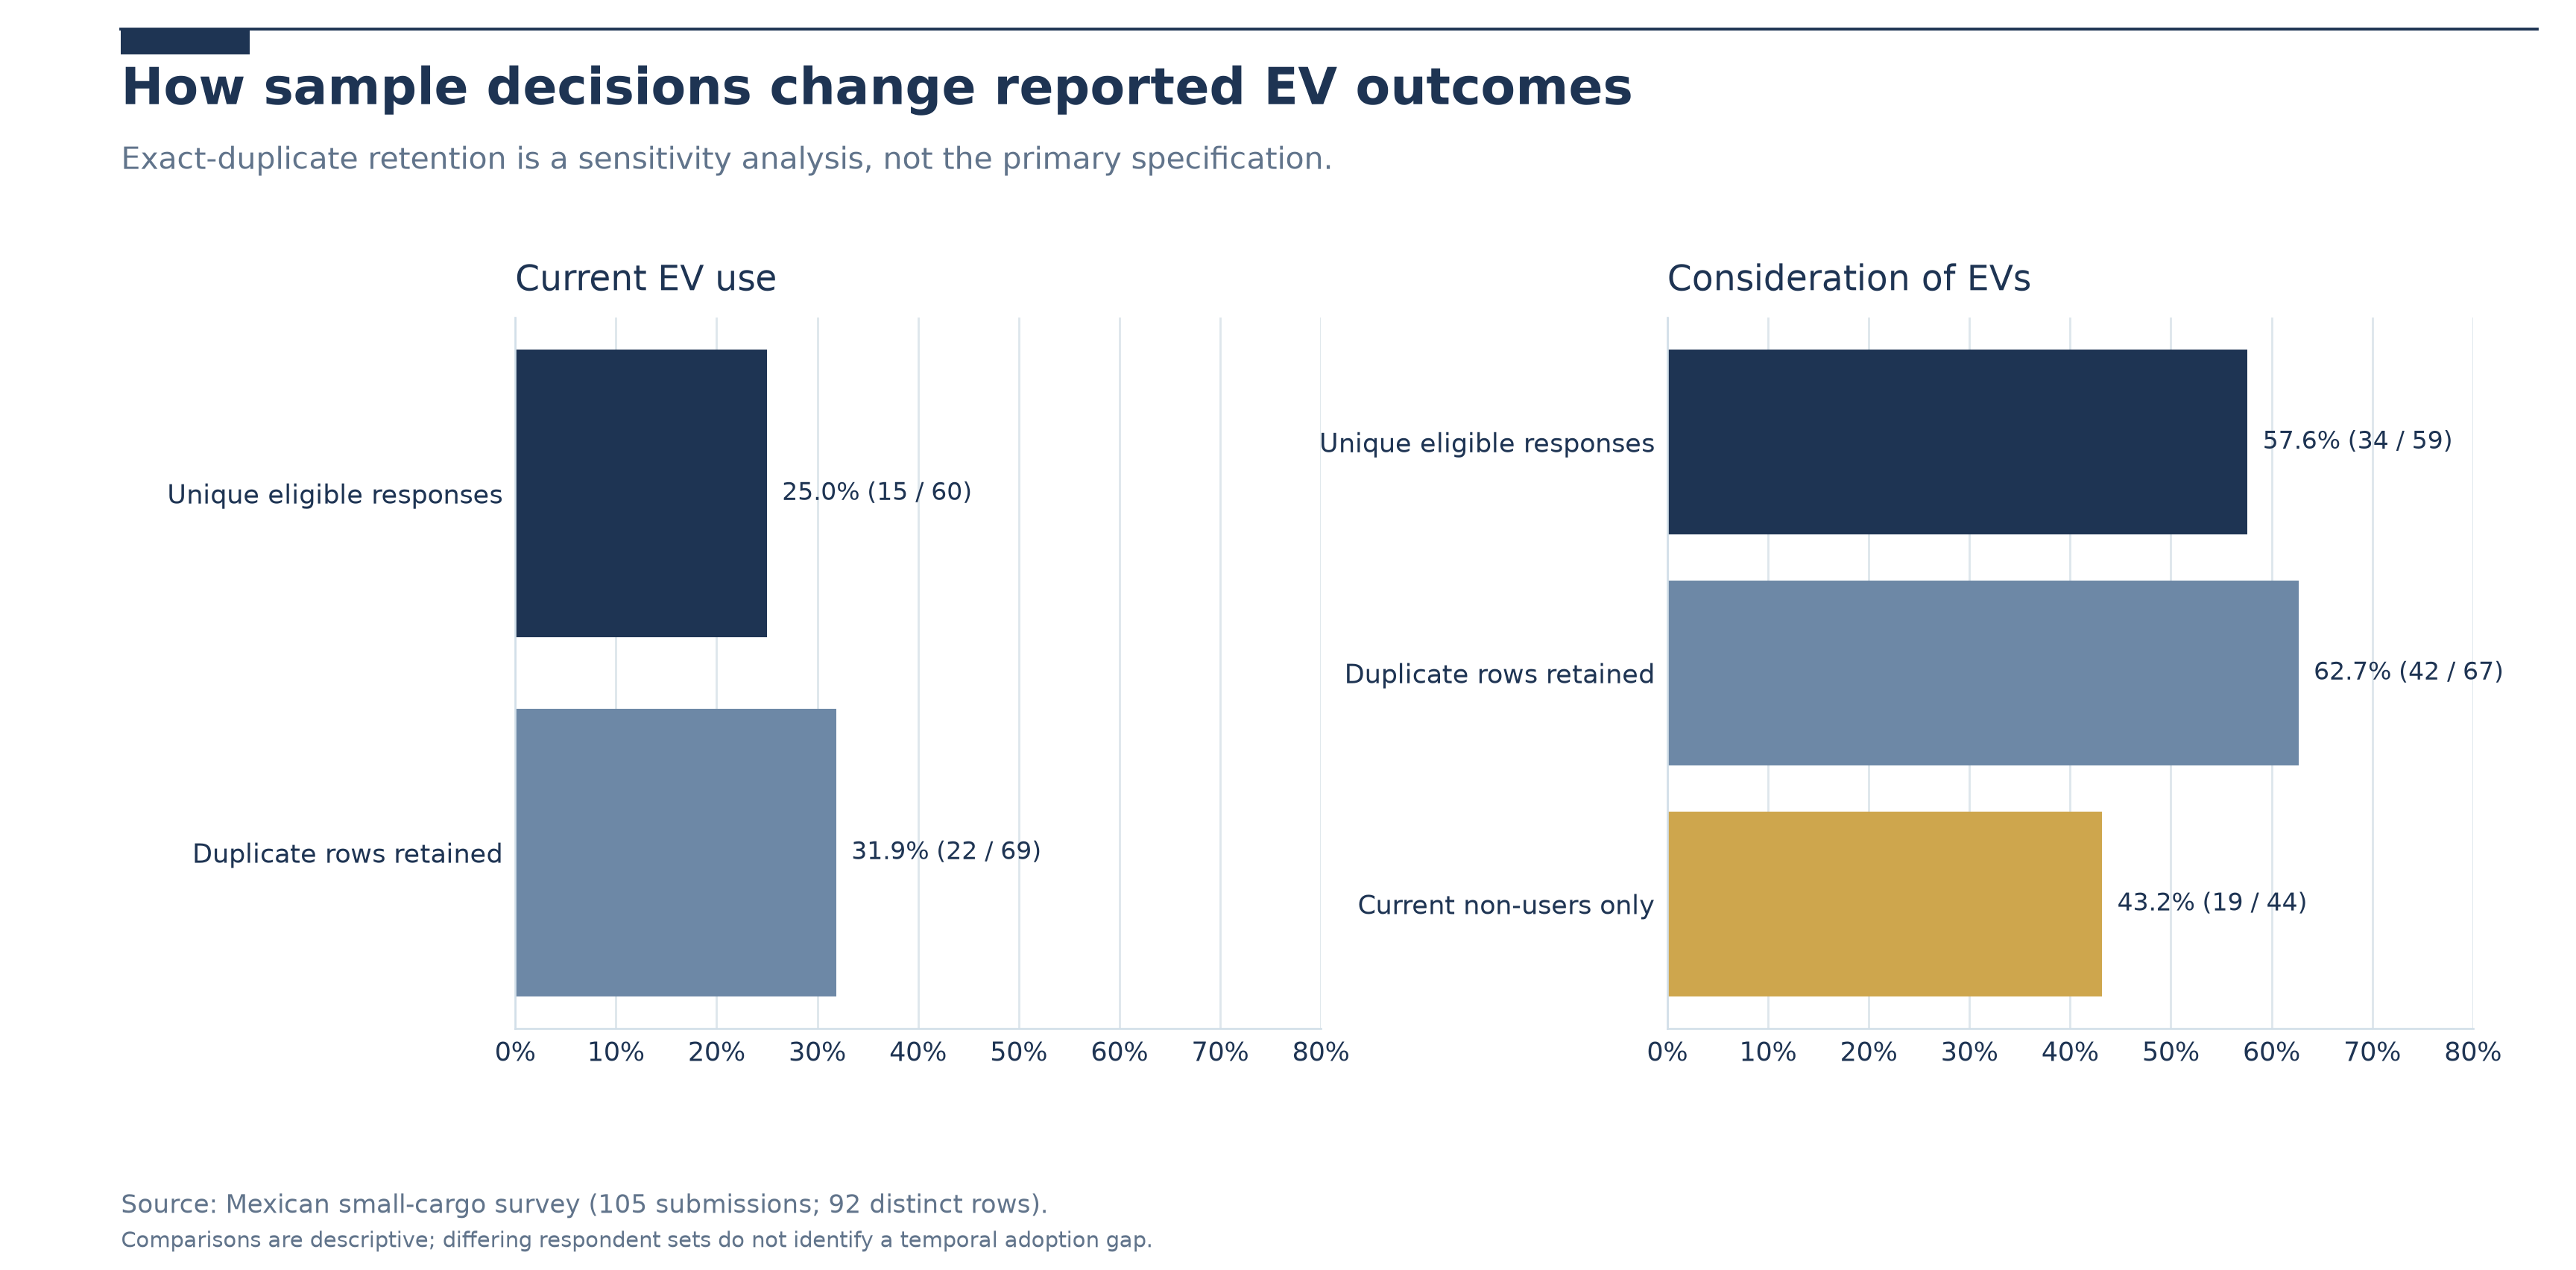

In [10]:
display(sensitivity_table(raw,eligible,SOURCE_INDEX))
plot_sample_sensitivity(eligible,raw,SOURCE_INDEX)
show_figure(FIGURES/'06_synthesis'/'01_duplicate_and_nonadopter_sensitivity.png')

## Interpretation and data limitations

- Companies self-selected into the survey; **sample percentages are not Mexico-wide adoption rates**.
- Valid denominators differ between current use and consideration.
- Free-text responses are harmonized conservatively, with original answers retained.
- Low-frequency categories are presented with counts and should not be described as statistically robust.
- A respondent's stated barrier is not a measured local charger shortage.
- Figures are centrally exported to `project-management/reports/figures/<section>/` and can be included in HTML posters using the SVG files.